# Organic molecules on Mars: rebuilding a Curiosity chromatogram

**CS85 project 11 · Thursday prototype**

**Question:** Can we see, in Curiosity's own raw chemistry data, the signals of organic molecules like benzene baked out of Martian rock?

**What this notebook does**
1. Downloads one experiment's raw data from NASA, plus the SAM science team's own results for the same experiment.
2. Finds the two gas-chromatograph (GC) runs inside the experiment.
3. Turns each run into a **chromatogram**: a graph where each peak is a substance coming out of the GC column.
4. Compares our peaks with the team's table: *when* each peak appears, *what* it is (from its mass "fingerprint"), and *how much* there is.

**Data sources** (please cite these)
- Curiosity SAM data, experiment 25387 (sol 1546): NASA Planetary Data System (PDS) Geosciences Node, MSL SAM archive. https://pds-geosciences.wustl.edu/missions/msl/sam.htm
- Reference mass spectra of benzene and toluene: NIST Chemistry WebBook, NIST Standard Reference Database 69. https://webbook.nist.gov/chemistry/

## How SAM works, in four steps

SAM (Sample Analysis at Mars) is the small chemistry lab inside the Curiosity rover.

1. **Oven:** rock powder is heated to several hundred °C, and gases come off.
2. **Trap:** some of that gas is caught and stored on a small trap.
3. **GC column:** the trap is flash-heated and the gas is pushed through a long, thin tube (the gas chromatograph). Different molecules travel through it at different speeds, so they come out one after another. The time a molecule takes is its **retention time**.
4. **Mass spectrometer:** as gas comes out, molecules are broken into charged pieces, and the instrument counts how many pieces of each mass arrive per second. The mass is written **m/z**. A whole benzene molecule weighs 78, so benzene shows up strongly at m/z 78. Toluene's strongest piece is at m/z 91.

## Setup

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import Image, display

# Find the project folder, whether this notebook runs from the repo root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / 'plots').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data'      # downloads are cached here (this folder is never committed)
PLOTS = ROOT / 'plots'    # figures are saved here

# One color per mass, used in every figure, plus gray tones for everything else
COLORS = {50: '#1baf7a', 78: '#2a78d6', 91: '#eb6834'}
LABELS = {50: 'm/z 50', 78: "m/z 78 (benzene's main mass)", 91: "m/z 91 (toluene's main mass)"}
INK, INK2, GRAY, AXIS, SHADE = '#0b0b0b', '#52514e', '#898781', '#c3c2b7', '#f0efec'

# A calm chart style: light gridlines, no top/right borders
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': AXIS,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'font.size': 10,
    'lines.linewidth': 1.4, 'legend.frameon': False,
})

## 1. Download the data

We download five files from NASA's archive and keep them in `data/`, so they're only downloaded once:
- the **raw mass-spectrometer readings** (about 38 MB),
- the team's **GC notes** (their peak list, with retention times and names),
- the team's **species table** (how big each peak is),
- the team's **chromatogram picture**,
- the team's **notes on the experiment**.

In [2]:
# The experiment we're studying. To look at a different SAM experiment, change these.
EID = 25387   # SAM experiment ID
SOL = 1546    # Mars day ("sol") of the experiment
PDS = f'https://pds-geosciences.wustl.edu/msl/msl-m-sam-2-rdr-l0-v1/mslsam_1xxx/data/eid{EID}/'

FILES = {
    'mass_spec':        f'level1b/sm{EID}f{SOL}rdr1b_spyr_qms_massdtc_2.tab',
    'gc_notes':         f'level2/sm{EID}f{SOL}rdr2__spyr_gc__notesxx_2.txt',
    'gc_species':       f'level2/sm{EID}f{SOL}rdr2__spyr_gc__species_2.csv',
    'gc_figure':        f'level2/sm{EID}f{SOL}rdr2__spyr_gc__species_2.jpg',
    'experiment_notes': f'level2/sm{EID}f{SOL}rdr2__spyr_qms_notesxx_2.txt',
}

def download(url, save_as):
    # Download a file once and keep it; later runs reuse the saved copy.
    save_as = Path(save_as)
    if not save_as.exists():
        save_as.parent.mkdir(parents=True, exist_ok=True)
        response = requests.get(url, timeout=300)
        response.raise_for_status()   # stop with a clear error if the download failed
        save_as.write_bytes(response.content)
        print(f'downloaded {save_as.name} ({len(response.content) / 1e6:.1f} MB)')
    return save_as

local = {}
for key, path in FILES.items():
    local[key] = download(PDS + path, DATA / f'sam_eid{EID}' / path)
print('All SAM files are ready in', (DATA / f'sam_eid{EID}').relative_to(ROOT))

All SAM files are ready in data/sam_eid25387


The team's notes describe what this sample was:

In [3]:
print(local['experiment_notes'].read_text())

This experiment was a drilled solid sample experiment, designated
CB OD2. It was the 2nd step of an opportunistic derivatization (OD)
experiment using a doggie-bag sample of the Cumberland drill hole
material. It took advantage of the presence of the derivatization
reagent, N-methyl-N-tert-butyldimethylsilyl-trifluoroacetamide
(MTBSTFA), which had been adsorbing onto the sample since it was
loaded into the pyrolysis cup several months previously. The
experiment was executed in two steps. In OD1, the oven was heated
to 250 deg C for removal of O2 from oxychlorine compounds. Gases
evolved at oven T up to 125 deg C were collected on the SAM
trap for later analysis by the GC. After OD1, the pyrolysis cup was
returned to the sample manipulation system for 48 hours to allow
MTBSTFA to readsorb onto the sample residue. In the second step, or
OD2, the oven was heated to 900 deg C and gas was collected on the
SAM trap for GC analysis throughout the entire temperature ramp.
For estimation of abu

**In plain words:** this was rock powder from the *Cumberland* drill hole, kept in a "doggie bag" on the rover and analysed again on sol 1546. A lab chemical called **MTBSTFA**, which SAM carries for a different kind of experiment, had been soaking into the powder for months, and the team used that on purpose. But MTBSTFA comes from Earth, so **some of the peaks in this experiment are made by it, not by Mars.** Keep that in mind when you look at the peaks.

## 2. Load the mass-spectrometer readings

Each row of the file is one reading: a time (in spacecraft-clock seconds), the mass being measured, the oven and GC temperatures, and the counts per second. The column order comes from the file's PDS label (the `.xml` file next to it in the archive).

In [4]:
ms = pd.read_csv(local['mass_spec'], skipinitialspace=True, header=0,
                 names=['time', 'mass', 'oven_T', 'gc_T', 'cps'], usecols=range(5))
ms['cps'] = pd.to_numeric(ms['cps'], errors='coerce')
ms['minutes'] = (ms['time'] - ms['time'].min()) / 60

# A few masses are also measured at in-between values (like 35.8). Keep whole-number masses only.
ms = ms[ms['mass'] % 1 == 0].copy()

print(f"{len(ms):,} readings of {ms['mass'].nunique()} different masses, "
      f"over {ms['minutes'].max():.0f} minutes")
ms.head()

357,319 readings of 537 different masses, over 240 minutes


,time,mass,oven_T,gc_T,cps,minutes
0,5.347812e+08,0.0,-79.59,11.84,58.83,0.000000
1,5.347812e+08,12.0,-77.56,11.84,111189.50,0.000667
2,5.347812e+08,12.0,-78.57,11.84,110953.88,0.001000
3,5.347812e+08,12.0,-79.59,11.84,106359.34,0.001333
4,5.347812e+08,12.0,-80.10,11.84,109716.86,0.001667


## 3. Read the team's results

The GC notes file is plain text. We pull three things out of it:
1. the clock time when each GC run started (when gas was "injected" into the column),
2. the peak list: peak number, the name the team gave it (if any), and retention time in seconds,
3. and, from the species table, each peak's size (its "area").

In [5]:
notes = local['gc_notes'].read_text()

# 1) Start time of each GC run, e.g. "534793066.5 s (sclk) for GC 4"
gc_start = {}
for clock_time, column in re.findall(r'([\d.]+) s \(sclk\) for GC (\d)', notes):
    gc_start[int(column)] = float(clock_time)

# 2) The peak list: lines like "peak 13 ; BENZENE ; 701"
rows = []
column = None
for line in notes.splitlines():
    if line.startswith('GC column'):          # a heading like "GC column 4 run"
        column = int(line.split()[2])
    match = re.match(r'peak (\d+) ;(.*);\s*(\d+)', line)
    if match:
        rows.append({'peak': int(match[1]), 'team_name': match[2].strip(),
                     'gc_column': column, 'team_time_s': float(match[3])})
team = pd.DataFrame(rows)

# 3) Peak sizes from the species table ("Peak 13" -> 13)
sizes = pd.read_csv(local['gc_species'])
sizes['peak'] = sizes['SPECIES'].str.replace('Peak ', '').astype(int)
team = team.merge(sizes[['peak', 'ABUNDANCE']], on='peak').rename(columns={'ABUNDANCE': 'team_area'})

# Run starts and trap flashes are instrument events, not molecules
team['event'] = team['team_name'].str.contains('INJECTION|FLASH')

t0 = ms['time'].min()
for column, start in gc_start.items():
    print(f'GC column {column} run starts {(start - t0) / 60:.1f} minutes into the experiment')
team

GC column 1 run starts 126.4 minutes into the experiment
GC column 4 run starts 198.6 minutes into the experiment


,peak,team_name,gc_column,team_time_s,team_area,event
0,0,GC1 INJECTION,1,0.0,0.000000e+00,True
1,1,,1,404.0,6.153390e+08,False
2,2,,1,498.0,4.737010e+08,False
3,3,,1,614.0,1.172900e+09,False
4,4,,1,842.0,1.501720e+08,False
5,5,,1,1049.0,1.387410e+07,False
6,6,,1,1102.0,3.568620e+07,False
7,7,,1,1969.0,8.978430e+07,False
8,8,GC4 IT FLASH 1,4,0.0,0.000000e+00,True
9,9,,4,178.0,4.788360e+07,False


Only **two** of the 26 entries have names: **benzene (peak 13)** and **toluene (peak 14)**, both in the column 4 run. Peaks 0, 8 and 18 are not molecules: they mark moments when gas was pushed into a column ("INJECTION", or "IT FLASH", which means flash-heating the trap). The other 21 are real peaks that the team numbered but didn't name.

## 4. The whole experiment at a glance

Before zooming in, here is the full four-hour experiment, with the stages labeled using the team's start times. Gaps in the lines are times when the file has no data.

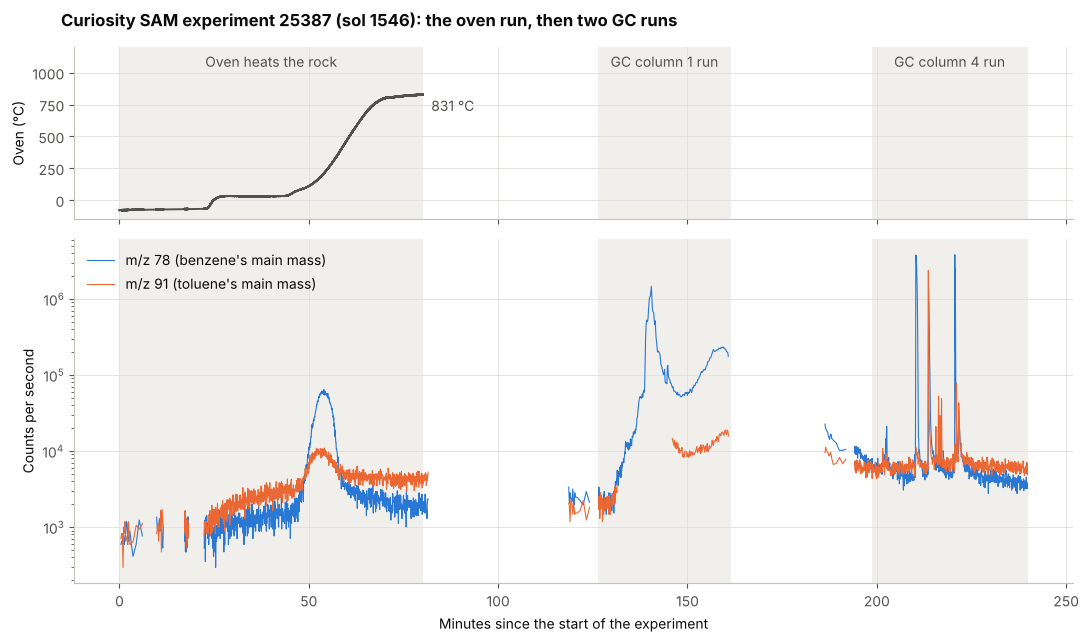

In [6]:
RUN_LENGTH = {1: 2100, 4: 1500}   # seconds of each GC run to show (the team's last peaks are at 1969 s and 1380 s)
start_min = {column: (start - t0) / 60 for column, start in gc_start.items()}

oven_peak = ms.loc[ms['oven_T'].idxmax()]
heating = ms[ms['minutes'] <= oven_peak['minutes']]

fig, (ax_T, ax_ms) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                                  gridspec_kw={'height_ratios': [1, 2]})

# Shade the three stages on both panels
stages = [('Oven heats the rock', 0, oven_peak['minutes']),
          ('GC column 1 run', start_min[1], start_min[1] + RUN_LENGTH[1] / 60),
          ('GC column 4 run', start_min[4], ms['minutes'].max())]
for name, start, end in stages:
    for ax in (ax_T, ax_ms):
        ax.axvspan(start, end, color=SHADE, lw=0, zorder=0)
    ax_T.text((start + end) / 2, 1020, name, ha='center', va='bottom', color=INK2)

# Top: the sample temperature in the oven while the rock is heated
ax_T.plot(heating['minutes'], heating['oven_T'], color=INK2)
ax_T.annotate(f"{oven_peak['oven_T']:.0f} °C", (oven_peak['minutes'], oven_peak['oven_T']),
              xytext=(6, -12), textcoords='offset points', color=INK2)
ax_T.set_ylim(-150, 1200)
ax_T.set_ylabel('Oven (°C)')

# Bottom: two masses, on a log scale so small and large signals both show
for mass in (78, 91):
    trace = ms[(ms['mass'] == mass) & (ms['cps'] > 0)].copy()
    trace.loc[trace['time'].diff() > 60, 'cps'] = np.nan   # don't draw lines across gaps in the data
    ax_ms.plot(trace['minutes'], trace['cps'], color=COLORS[mass], lw=0.8, label=LABELS[mass])
ax_ms.set_yscale('log')
ax_ms.set_ylabel('Counts per second')
ax_ms.set_xlabel('Minutes since the start of the experiment')
ax_ms.legend(loc='upper left')
fig.suptitle(f'Curiosity SAM experiment {EID} (sol {SOL}): the oven run, then two GC runs',
             fontweight='bold', x=0.06, ha='left')
fig.tight_layout()
fig.savefig(PLOTS / 'mars_sam_experiment_overview.png', dpi=150)
plt.show()

First the oven heats the rock (left), and the mass spectrometer measures the gas directly. Then come the two GC runs. The tall, narrow spikes in the column 4 run are peaks from the team's list, including benzene and toluene.

## 5. The chromatograms

Now each GC run on its own, with time counted from the moment gas entered the column (the retention time), the same way the team counts it. We plot the three masses that carry the biggest peaks on a normal (linear) scale, like the team's figure. Gray triangles mark every peak in the team's table, with its number.

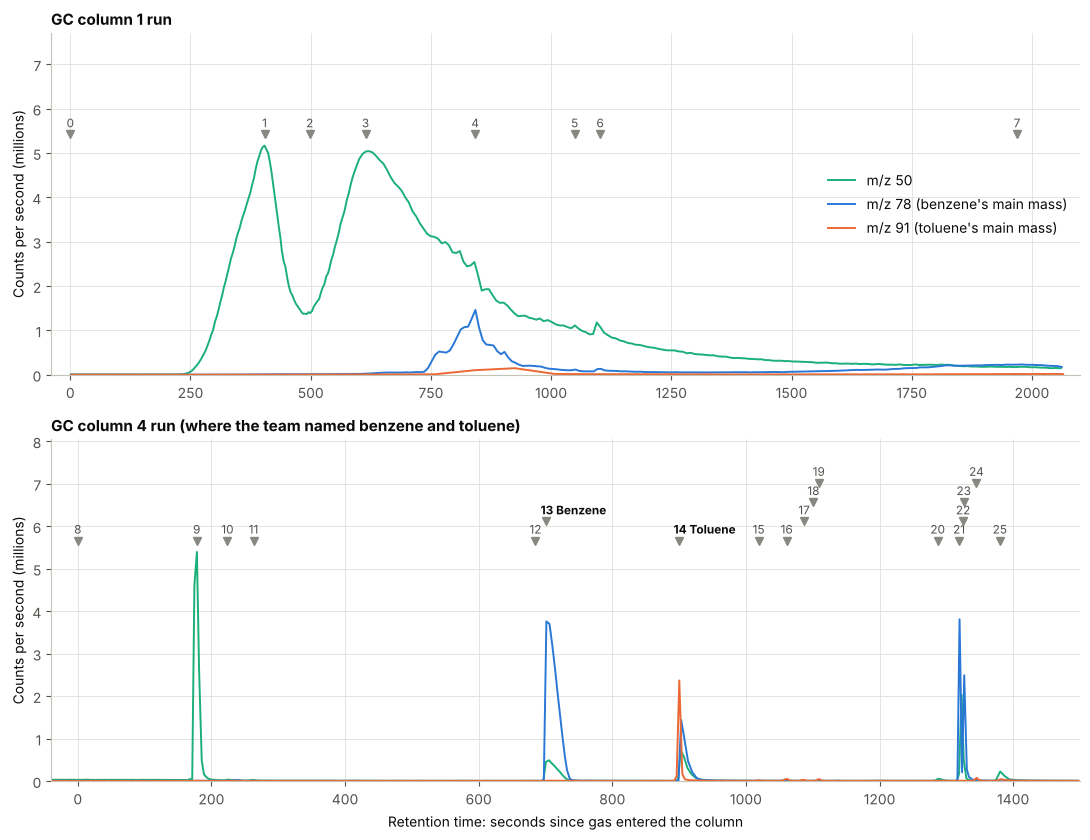

In [7]:
def gc_run(column):
    # Readings from one GC run, with time counted from the start of the run (retention time).
    # We keep one minute before the start too, to measure the background level.
    start = gc_start[column]
    run = ms[(ms['time'] >= start - 60) & (ms['time'] <= start + RUN_LENGTH[column])].copy()
    run['rt'] = run['time'] - start
    return run

runs = {column: gc_run(column) for column in gc_start}

def mark_team_peaks(ax, peaks, y):
    # A gray triangle and the team's number above each of their peaks. Named peaks get bold labels.
    level, last_time = 0, -1e9
    for _, p in peaks.sort_values('team_time_s').iterrows():
        # stagger the labels of peaks that are close together so they don't overlap
        level = level + 1 if p['team_time_s'] - last_time < 30 else 0
        last_time = p['team_time_s']
        y_here = y * (1 + 0.08 * level)
        ax.plot(p['team_time_s'], y_here, 'v', color=GRAY, ms=6, zorder=3)
        named = p['team_name'] != '' and not p['event']
        ax.annotate(f"{p['peak']} {p['team_name'].title()}" if named else str(p['peak']),
                    (p['team_time_s'], y_here), xytext=(-4 if named else 0, 5), textcoords='offset points',
                    ha='left' if named else 'center', fontsize=8.5,
                    color=INK if named else INK2, fontweight='bold' if named else 'normal')

fig, axes = plt.subplots(2, 1, figsize=(11, 8.5))
titles = {1: 'GC column 1 run', 4: 'GC column 4 run (where the team named benzene and toluene)'}
for ax, column in zip(axes, (1, 4)):
    run = runs[column]
    for mass in (50, 78, 91):
        trace = run[run['mass'] == mass]
        ax.plot(trace['rt'], trace['cps'] / 1e6, color=COLORS[mass], label=LABELS[mass])
    top = run.loc[run['mass'].isin([50, 78, 91]), 'cps'].max() / 1e6 * 1.05
    mark_team_peaks(ax, team[team['gc_column'] == column], top)
    ax.set_ylim(0, top * 1.42)
    ax.set_xlim(-40, RUN_LENGTH[column])
    ax.set_title(titles[column], loc='left')
    ax.set_ylabel('Counts per second (millions)')
axes[0].legend(loc='center right')
axes[1].set_xlabel('Retention time: seconds since gas entered the column')
fig.tight_layout()
fig.savefig(PLOTS / 'mars_sam_chromatograms.png', dpi=150)
plt.show()

For comparison, here is the team's own chromatogram from the archive. Their x-axis is spacecraft-clock time instead of retention time, and they plot four more masses (51, 52, 77 and 92):

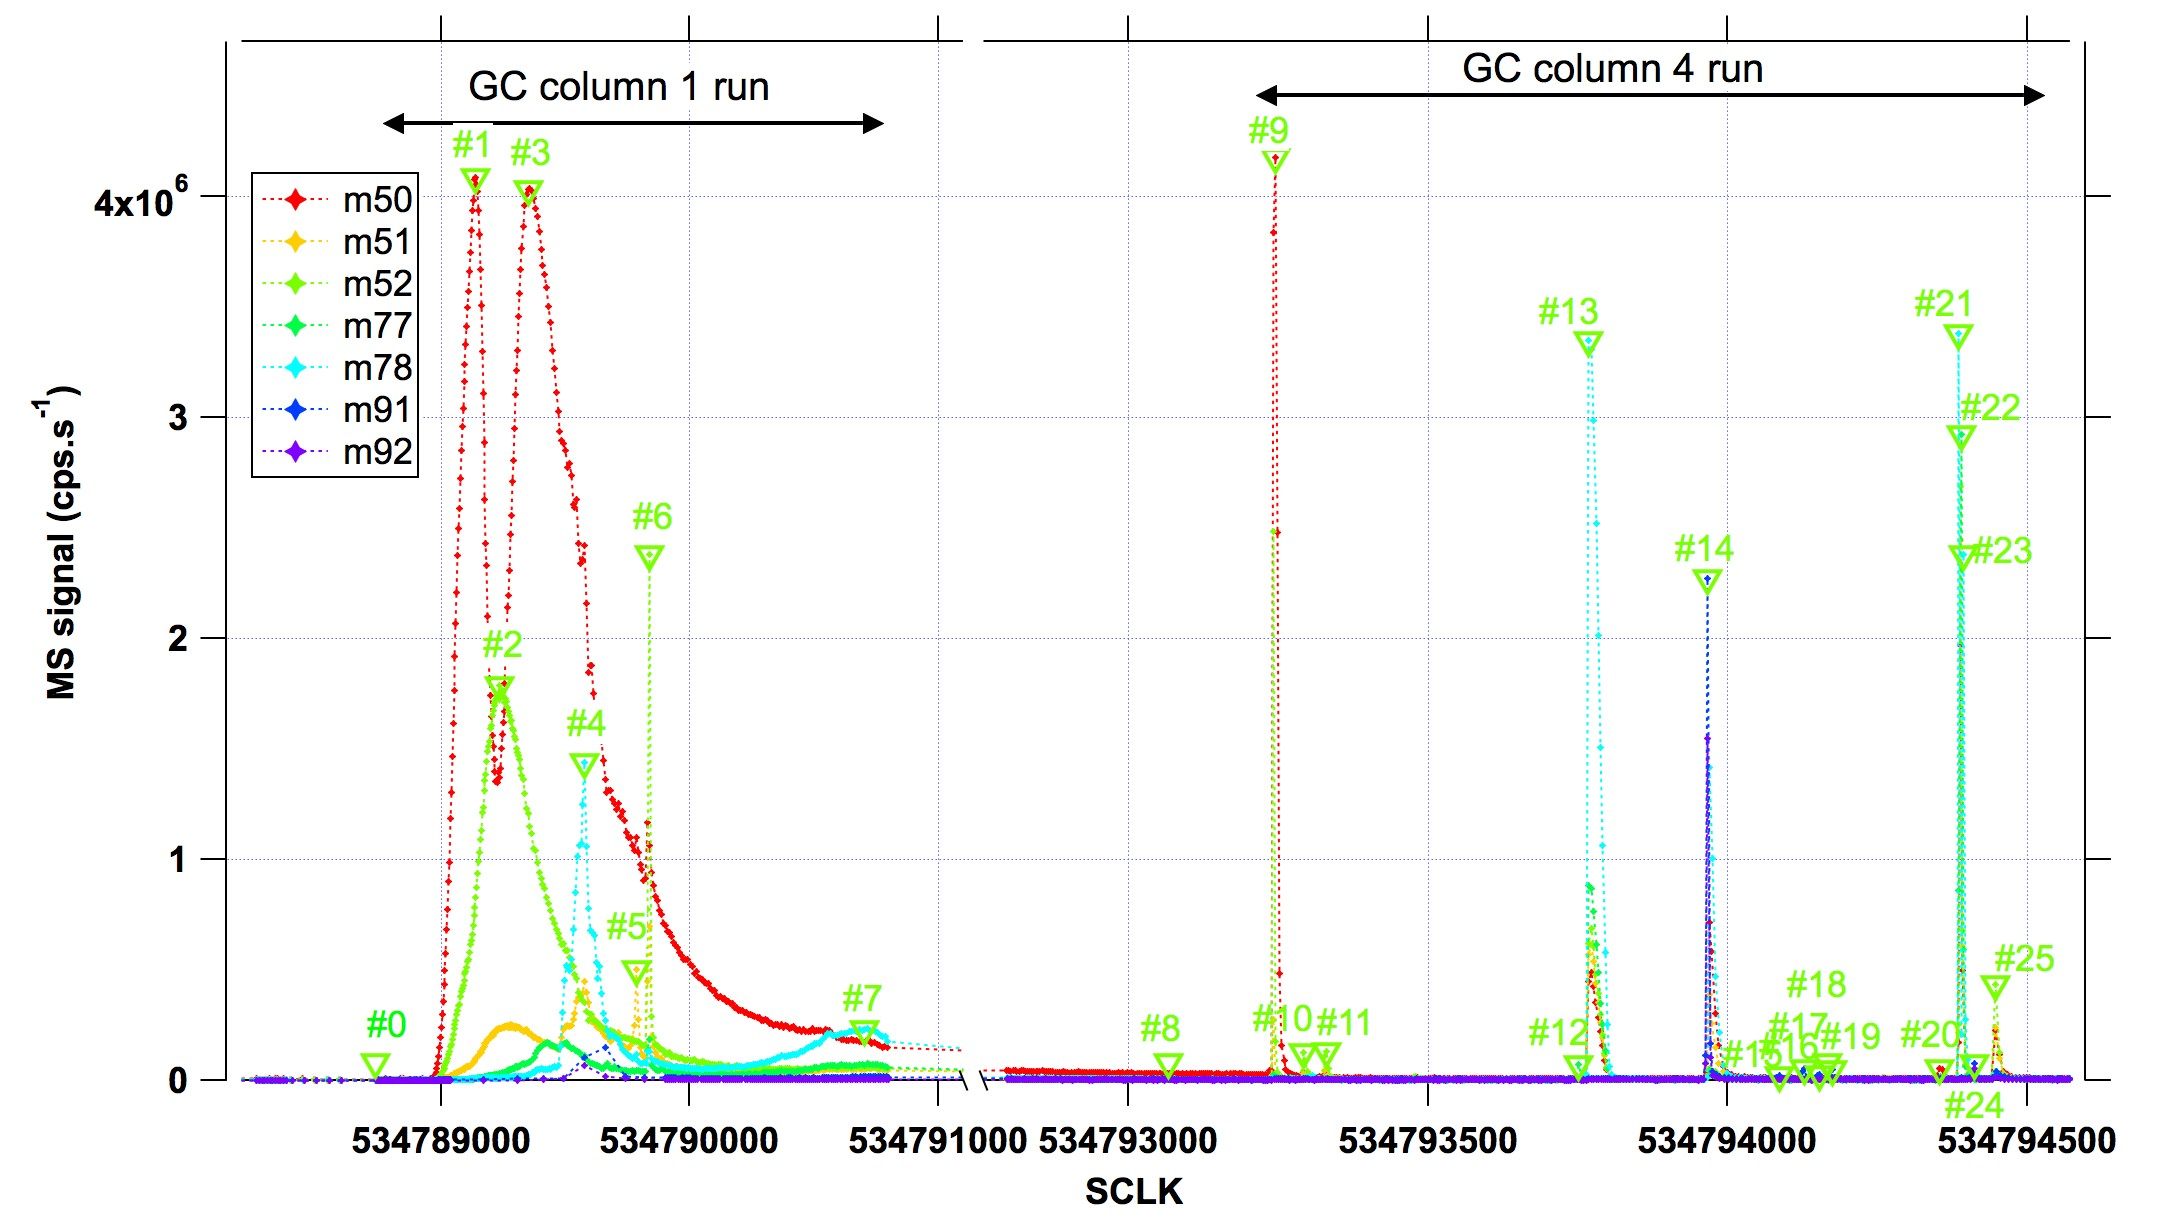

In [8]:
display(Image(filename=local['gc_figure'], width=900))

## 6. Do our peaks line up with the team's table?

For each peak in the team's list, we look at the raw readings within a few seconds of the team's time and ask:
- **When** is the signal highest? That's our retention time.
- **Which masses** rise the most? That's the peak's "fingerprint" (its mass spectrum).
- **How much does that fingerprint look like benzene or toluene?** We compare it with NIST's reference spectra using a **similarity score** from 0 (nothing in common) to 1 (the same pattern).

One limit: the mass spectrometer measures each mass only every few seconds, because it cycles through many masses. So our times can only be as precise as that.

In [9]:
WINDOW = {1: 15, 4: 8}   # how many seconds either side of the team's time we look (about two scans)

def spectrum_at(column, time_s):
    # The fingerprint at a moment in a GC run: the highest reading of each mass near time_s,
    # minus that mass's usual level 20-60 seconds earlier (the background).
    run = runs[column]
    near = run[(run['rt'] - time_s).abs() <= WINDOW[column]]
    before = run[(run['rt'] >= time_s - 60) & (run['rt'] <= time_s - 20)]
    spectrum = near.groupby('mass')['cps'].max() - before.groupby('mass')['cps'].median()
    return spectrum.dropna().clip(lower=0)

def nist_spectrum(nist_id):
    # Reference mass spectrum from the NIST Chemistry WebBook (JCAMP-DX text format)
    url = f'https://webbook.nist.gov/cgi/cbook.cgi?JCAMP={nist_id}&Index=0&Type=Mass'
    text = download(url, DATA / 'nist' / f'{nist_id}.jdx').read_text()
    table = text.split('##PEAK TABLE=(XY..XY)')[1].split('##END')[0]
    return pd.Series({int(m): float(i) for m, i in re.findall(r'(\d+),(\d+)', table)})

REFERENCE = {'benzene': nist_spectrum('C71432'),    # NIST IDs come from the CAS numbers 71-43-2
             'toluene': nist_spectrum('C108883')}   # and 108-88-3

def similarity(a, b, lightest=35):
    # Cosine similarity of two spectra: 1 = same pattern, 0 = nothing in common.
    # Masses below 35 are skipped: water, nitrogen and oxygen are always in the instrument.
    masses = sorted(m for m in set(a.index) | set(b.index) if m >= lightest)
    x = a.reindex(masses, fill_value=0).to_numpy()
    y = b.reindex(masses, fill_value=0).to_numpy()
    return float(x @ y / np.sqrt((x @ x) * (y @ y)))

rows = []
for _, p in team[~team['event']].iterrows():
    column, team_time = p['gc_column'], p['team_time_s']
    spectrum = spectrum_at(column, team_time)
    heavy = spectrum[spectrum.index >= 45]          # skip the light gases when ranking masses
    strongest = heavy.idxmax()
    run = runs[column]
    near = run[(run['mass'] == strongest) & ((run['rt'] - team_time).abs() <= WINDOW[column])]
    our_time = near.loc[near['cps'].idxmax(), 'rt']
    rows.append({'peak': p['peak'], 'GC column': column, 'team name': p['team_name'].title(),
                 'team time (s)': team_time, 'our time (s)': round(our_time, 1),
                 'difference (s)': round(our_time - team_time, 1),
                 'strongest masses': ', '.join(str(int(m)) for m in heavy.nlargest(3).index),
                 'benzene score': round(similarity(spectrum, REFERENCE['benzene']), 2),
                 'toluene score': round(similarity(spectrum, REFERENCE['toluene']), 2)})
comparison = pd.DataFrame(rows)
comparison

,peak,GC column,team name,team time (s),our time (s),difference (s),strongest masses,benzene score,toluene score
0,1,1,,404.0,404.2,0.2,"50, 65, 52",0.20,0.09
1,2,1,,498.0,498.7,0.7,"52, 47, 81",0.05,0.03
2,3,1,,614.0,622.6,8.6,"66, 50, 53",0.07,0.03
3,4,1,,842.0,844.6,2.6,"127, 69, 78",0.18,0.00
4,5,1,,1049.0,1057.2,8.2,"48, 69, 51",0.05,0.01
5,6,1,,1102.0,1115.3,13.3,"147, 117, 149",0.07,0.03
6,7,1,,1969.0,1961.8,-7.2,"85, 78, 47",0.33,0.09
7,9,4,,178.0,182.0,4.0,"66, 50, 65",0.17,0.06
8,10,4,,224.0,224.5,0.5,"52, 47, 45",0.08,0.07
9,11,4,,263.0,263.5,0.5,"53, 52, 51",0.12,0.02


In [10]:
# How often each mass is measured in each run (seconds between readings of m/z 78)
scan_time = {column: runs[column].loc[runs[column]['mass'] == 78, 'rt'].diff().median() for column in runs}
within = comparison['difference (s)'].abs() <= comparison['GC column'].map(scan_time)
print('Seconds between readings of the same mass:', {c: round(float(s), 1) for c, s in scan_time.items()})
print(f"{within.sum()} of {len(comparison)} peaks: our time is within one reading of the team's time")
print(f"Largest difference: {comparison['difference (s)'].abs().max():.1f} s")

Seconds between readings of the same mass: {1: 7.5, 4: 3.8}
17 of 23 peaks: our time is within one reading of the team's time
Largest difference: 13.3 s


**What the table shows**
- **Timing:** for 17 of the 23 peaks, our time is within one reading of the team's (readings of the same mass are 3.8 s apart in the column 4 run and 7.5 s apart in column 1). The bigger differences are broad peaks in the column 1 run, plus peaks 22 and 23, which the team lists only 1 second apart. Our data can't separate those two, so they get the same time as peak 21.
- **Benzene:** peak 13 is the only peak whose fingerprint matches benzene almost perfectly (score 0.99).
- **Peaks 21 to 23** also look a lot like benzene (score 0.85, and their strongest masses are benzene's 78, 77 and 52), but the team didn't name them. That's a good open question for your demo.
- **Toluene:** peak 14 scores only 0.42, because something else comes out of the column at the same moment (see section 7).
- **Clues to unnamed peaks:** peaks 15, 16, 17 and 19 all have strongest masses 91 and 106. Toluene's heavier cousins with a weight of 106 (xylene and ethylbenzene) give that pattern, so these peaks might be one of them. That's a guess to test, not a result. Peaks 6 and 25 have masses 147 to 149 (and 73 for peak 25), which are typical of silicon-containing compounds like the reagent's by-products.

## 7. Fingerprints: benzene and toluene vs. NIST

These are mirror plots. The top half shows what Curiosity measured at the peak, with the background removed. The bottom half, flipped upside down, is NIST's reference spectrum measured in a lab on Earth. If the bars line up, it's the same molecule. Both halves are scaled so their tallest bar is 100.

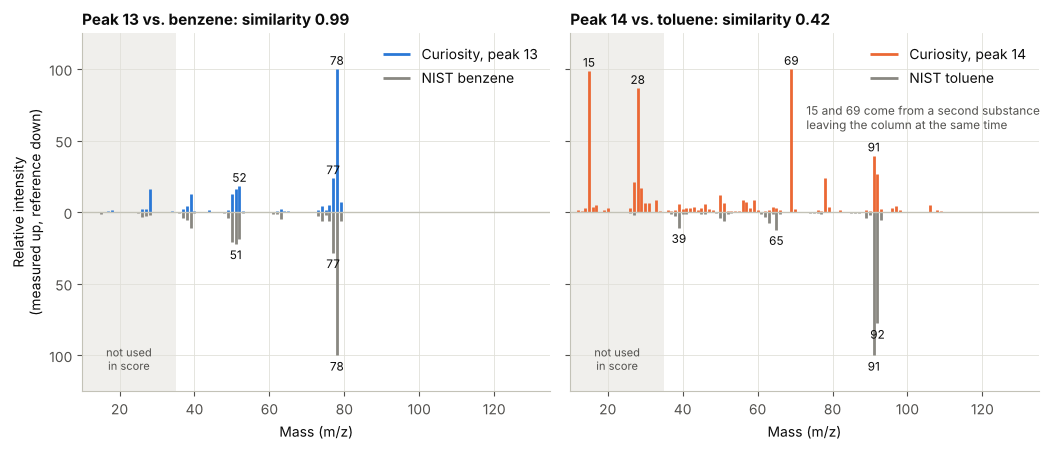

In [11]:
def label_tallest(ax, spectrum, sign, how_many=4):
    # Write the mass above (or below) the tallest bars, skipping a bar whose label would
    # sit right on top of one already written (next-door masses with similar heights)
    done = []
    for m in spectrum.sort_values(ascending=False).index[:how_many]:
        if any(abs(m - m2) <= 2 and abs(spectrum[m] - spectrum[m2]) < 10 for m2 in done):
            continue
        done.append(m)
        ax.annotate(str(int(m)), (m, sign * spectrum[m]), xytext=(0, 3 if sign > 0 else -11),
                    textcoords='offset points', ha='center', fontsize=8.5)

def mirror_plot(ax, measured, reference, color, measured_label, reference_label):
    measured = 100 * measured / measured.max()
    reference = 100 * reference / reference.max()
    ax.axvspan(10, 35, color=SHADE, lw=0, zorder=0)
    ax.text(22.5, -112, 'not used\nin score', ha='center', va='bottom', fontsize=8, color=INK2)
    ax.vlines(measured.index, 0, measured.values, color=color, lw=2, label=measured_label)
    ax.vlines(reference.index, 0, -reference.values, color=GRAY, lw=2, label=reference_label)
    ax.axhline(0, color=AXIS, lw=1)
    label_tallest(ax, measured, +1)
    label_tallest(ax, reference, -1)
    ax.set_xlim(10, 135)
    ax.set_ylim(-125, 125)
    ax.set_yticks([-100, -50, 0, 50, 100], ['100', '50', '0', '50', '100'])
    ax.set_xlabel('Mass (m/z)')
    ax.legend(loc='upper right')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (peak, molecule, mass) in zip(axes, [(13, 'benzene', 78), (14, 'toluene', 91)]):
    spectrum = spectrum_at(4, team.set_index('peak').loc[peak, 'team_time_s'])
    spectrum = spectrum[(spectrum.index >= 10) & (spectrum.index <= 135)]
    score = similarity(spectrum, REFERENCE[molecule])
    mirror_plot(ax, spectrum, REFERENCE[molecule], COLORS[mass],
                f'Curiosity, peak {peak}', f'NIST {molecule}')
    ax.set_title(f'Peak {peak} vs. {molecule}: similarity {score:.2f}', loc='left')
axes[1].text(73, 76, '15 and 69 come from a second substance\nleaving the column at the same time',
             va='top', fontsize=8.5, color=INK2)
axes[0].set_ylabel('Relative intensity\n(measured up, reference down)')
fig.tight_layout()
fig.savefig(PLOTS / 'mars_sam_fingerprints_vs_nist.png', dpi=150)
plt.show()

- **Benzene (left):** Curiosity's peak 13 has the same bars as NIST's benzene: a tall 78, then 77, and a small group at 50 to 52. A similarity of 0.99 is about as good as a match gets, so this peak really is benzene.
- **Toluene (right):** toluene's two main bars, 91 and 92, are there in roughly the right ratio. But the tallest bars, 69 and 15, aren't toluene at all. A second, unidentified substance comes out of the column at almost the same moment, which is why the score is only 0.42. One peak in time can contain two molecules, and the fingerprint is how you notice.

## 8. How much benzene and toluene?

The team's species table gives each peak's size as the **area** under the trace of its strongest mass, with no background removed (their GC notes say so). Area = counts per second × seconds, so the unit is simply counts. We do the same thing: add up the m/z 78 readings around peak 13 and the m/z 91 readings around peak 14, from 20 seconds before the team's time to 40 seconds after.

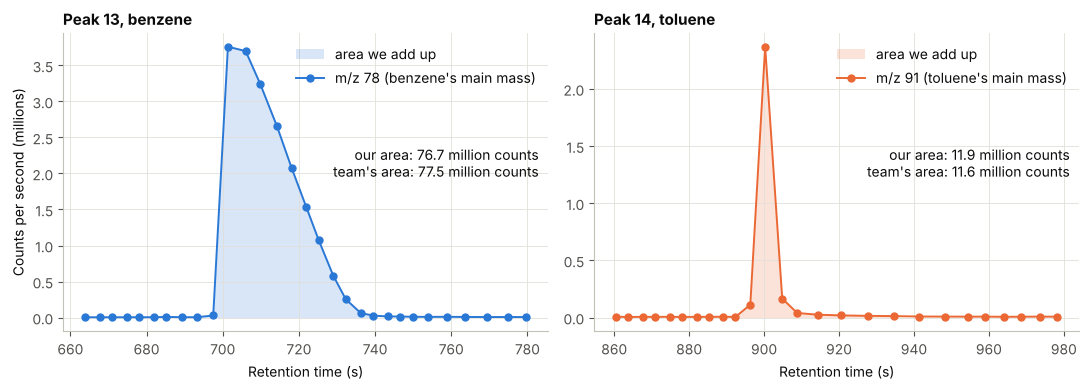

,peak,molecule,mass used,readings used,our area,team's area,ours ÷ theirs
0,13,benzene,78,16,7.67e+07,7.75e+07,0.99
1,14,toluene,91,12,1.19e+07,1.16e+07,1.03


In [12]:
def peak_area(column, mass, time_s, before=20, after=40):
    # Area under one mass's trace around a peak (no background removed, like the team)
    run = runs[column]
    used = run[(run['mass'] == mass) & (run['rt'] >= time_s - before) & (run['rt'] <= time_s + after)]
    return np.trapezoid(used['cps'], used['rt']), used

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
area_rows = []
for ax, (peak, molecule, mass) in zip(axes, [(13, 'benzene', 78), (14, 'toluene', 91)]):
    p = team.set_index('peak').loc[peak]
    area, used = peak_area(4, mass, p['team_time_s'])
    run = runs[4]
    around = run[(run['mass'] == mass) & run['rt'].between(p['team_time_s'] - 40, p['team_time_s'] + 80)]
    ax.fill_between(used['rt'], used['cps'] / 1e6, color=COLORS[mass], alpha=0.18, lw=0, label='area we add up')
    ax.plot(around['rt'], around['cps'] / 1e6, '-o', color=COLORS[mass], ms=5, label=LABELS[mass])
    ax.text(0.98, 0.62, f"our area: {area / 1e6:.1f} million counts\n"
                        f"team's area: {p['team_area'] / 1e6:.1f} million counts",
            transform=ax.transAxes, ha='right', va='top')
    ax.set_title(f'Peak {peak}, {molecule}', loc='left')
    ax.set_xlabel('Retention time (s)')
    ax.legend(loc='upper right')
    area_rows.append({'peak': peak, 'molecule': molecule, 'mass used': mass, 'readings used': len(used),
                      'our area': f'{area:.3g}', "team's area": f"{p['team_area']:.3g}",
                      'ours ÷ theirs': round(area / p['team_area'], 2)})
axes[0].set_ylabel('Counts per second (millions)')
fig.tight_layout()
fig.savefig(PLOTS / 'mars_sam_benzene_toluene_areas.png', dpi=150)
plt.show()
pd.DataFrame(area_rows)

Our areas come out at **99% (benzene)** and **103% (toluene)** of the team's numbers. So, starting from the raw readings, we get the same peak sizes the team reported. Small differences are expected: each mass is measured only about every 4 seconds, so each peak is drawn from a handful of readings (the dots), and our choice of window decides exactly where the edges are.

These areas measure the size of the signal, not an amount in grams. Turning them into "how much benzene" needs SAM's calibration.

## 9. What we found

1. **We rebuilt the chromatograms from raw counts.** The experiment has an oven run and then two GC runs, and our chromatograms show the same peaks as the team's own figure.
2. **Our peaks line up with the team's table.** For 17 of 23 peaks we get the same retention time to within one reading.
3. **Benzene is clearly there.** Peak 13's fingerprint matches NIST's benzene with a similarity of 0.99, and our peak area is within 1% of the team's.
4. **Toluene is there, but it shares its peak.** Its masses 91 and 92 are present and our area is within 3% of the team's, but a second, unidentified substance comes out at the same time.
5. **Most peaks have no name.** The team named only 2 of 23 peaks. Some of the others are probably by-products of the MTBSTFA reagent, which comes from Earth.

### Caveats (worth saying in the demo)
- **Finding benzene doesn't prove it came from Mars.** In SAM, benzene and toluene can also come from the instrument itself, for example from the material in its gas trap. Showing that organic molecules are really Martian takes more evidence, such as molecules containing chlorine from Martian salts. Freissinet et al. (2015) studied this same Cumberland rock.
- **Time precision:** each mass is measured only every 3.8 s (column 4) or 7.5 s (column 1), so peaks that are close together blur into one.
- **Simple scores:** we compare each peak with only two reference spectra, and the score ignores masses below 35.

### Next steps
- **Test the open questions:** compare peaks 15 to 19 with NIST spectra of xylene and ethylbenzene, and look more closely at peaks 21 to 23, using the `nist_spectrum()` and `similarity()` functions above.
- **Stretch goal (compare two rocks):** change `EID` and `SOL` at the top to another SAM experiment that has a `level2` species table in the archive, adjust the file names in `FILES` if needed, and rerun.

### References
- Mars Science Laboratory SAM data, experiment 25387 (sol 1546): files `level1b/..._qms_massdtc_2.tab`, `level2/..._gc__notesxx_2.txt`, `level2/..._gc__species_2.csv/.jpg` and `level2/..._qms_notesxx_2.txt`. NASA Planetary Data System, Geosciences Node. https://pds-geosciences.wustl.edu/missions/msl/sam.htm
- NIST Chemistry WebBook, NIST Standard Reference Database Number 69: mass spectra of benzene (CAS 71-43-2) and toluene (CAS 108-88-3). https://webbook.nist.gov/chemistry/
- Freissinet, C. et al. (2015). Organic molecules in the Sheepbed Mudstone, Gale Crater, Mars. *Journal of Geophysical Research: Planets*, 120, 495–514.